# NETDEFY — Notebook 02: Data Quality, Deduplication & Ambiguity Tracking

**Project:** NETDEFY — Network Defense Intelligence  
**Notebook:** `notebooks/02_data_quality_analysis.ipynb`  
**Purpose:** Forensic audit of missing values, infinities, physical duplicate records, feature-only deduplication, conflicting ground-truth labels, and benchmark ambiguity tracking.  
**Historical Provenance:** Phase 2 Forensic Inspection, Phase 3 Preprocessing, Phase 3.1 Duplicate Policy & Label Integrity Audit (`reports/PHASE3_1_DUPLICATE_LABEL_INTEGRITY_AUDIT.md`), and Phase 3.2 Benchmark Sampling.  
**Provenance & Calculation Methodology:**
- Missing and infinite values are audited directly from the forensic manifest (`reports/dataset_forensic_summary.json`) and reconciled against partition imputation manifests.
- Feature deduplication accounting is verified against `reports/phase3_1_duplicate_audit.json` and `data/processed/{train,validation,test}/*_dedup.parquet`.
- Benchmark test ambiguity is computed directly from `data/benchmark/v1/test.parquet` and cross-referenced with `data/benchmark/v1/metadata/ambiguity_manifest.json`.

---

### Research Questions
1. Where do missing and infinite values originate in network flow telemetry, and how does NETDEFY guarantee zero-leakage imputation?
2. What network engineering phenomena generate duplicate flow records in raw packet captures?
3. What is the mathematical and security consequence of deduplicating strictly on continuous flow features versus preserving duplicate keys?
4. Can two network flows possess identical flow-dynamics features but carry contradictory ground-truth labels?
5. How does ambiguity manifest in the 50,000-flow benchmark holdout, and what is the exact reconciliation of the 3,287 vs 3,254 PortScan figure?


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repository-aware path resolution
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
reports_dir = project_root / "reports"
benchmark_dir = project_root / "data" / "benchmark" / "v1"

# Styling configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "axes.edgecolor": "#cccccc",
        "axes.linewidth": 0.8,
        "grid.color": "#eaeaea",
        "grid.linestyle": "--",
    }
)

print(f"Project root resolved to: {project_root}")

Project root resolved to: /Users/nitinkumar/Documents/Netdefy


## 1. Missing & Infinite Value Forensics & Accounting Reconciliation

In Phase 2, forensic inspection evaluated missing (`NaN`) and infinite (`inf`) values across all 2,830,743 rows and 79 columns.
We load `reports/dataset_forensic_summary.json` and reconcile all documented counts.


In [2]:
with open(reports_dir / "dataset_forensic_summary.json") as f:
    forensic = json.load(f)

quality_records = []
for fr in forensic["file_reports"]:
    quality_records.append(
        {
            "Filename": fr["filename"]
            .replace(".pcap_ISCX.csv", "")
            .replace("-WorkingHours", "")
            .replace("-workingHours", ""),
            "Total Rows": fr["total_rows"],
            "Missing Values (NaN)": fr["total_missing_values"],
            "Infinite Values (inf)": fr["total_infinite_values"],
            "Bytes/s inf": fr["infinite_values_per_column"].get("Flow Bytes/s", 0),
            "Packets/s inf": fr["infinite_values_per_column"].get("Flow Packets/s", 0),
        }
    )

df_quality = (
    pd.DataFrame(quality_records)
    .sort_values("Infinite Values (inf)", ascending=False)
    .reset_index(drop=True)
)
tot_missing = df_quality["Missing Values (NaN)"].sum()
tot_inf = df_quality["Infinite Values (inf)"].sum()
tot_inf_bytes = df_quality["Bytes/s inf"].sum()
tot_inf_pkts = df_quality["Packets/s inf"].sum()

print(f"Total Original Missing Cells (NaN): {tot_missing:,} (All 1,358 in 'Flow Bytes/s')")
print(f"Total Infinite Cells (+inf / -inf): {tot_inf:,}")
print(f"  • Infinite values in 'Flow Bytes/s':   {tot_inf_bytes:,}")
print(f"  • Infinite values in 'Flow Packets/s': {tot_inf_pkts:,}")
print(f"Total Imputed Values in Pipeline (NaNs + Converted Infs): {tot_missing + tot_inf:,}")
print()
print(
    df_quality[
        [
            "Filename",
            "Total Rows",
            "Missing Values (NaN)",
            "Infinite Values (inf)",
            "Bytes/s inf",
            "Packets/s inf",
        ]
    ].to_string(index=False)
)

Total Original Missing Cells (NaN): 1,358 (All 1,358 in 'Flow Bytes/s')
Total Infinite Cells (+inf / -inf): 4,376
  • Infinite values in 'Flow Bytes/s':   1,509
  • Infinite values in 'Flow Packets/s': 2,867
Total Imputed Values in Pipeline (NaNs + Converted Infs): 5,734

                        Filename  Total Rows  Missing Values (NaN)  Infinite Values (inf)  Bytes/s inf  Packets/s inf
                       Wednesday      692703                  1008                   1586          289           1297
                          Monday      529918                    64                    810          373            437
       Friday-Afternoon-PortScan      286467                    15                    727          356            371
Thursday-Afternoon-Infilteration      288602                    18                    396          189            207
                         Tuesday      445909                   201                    327           63            264
     Thursday-Morni

<string>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


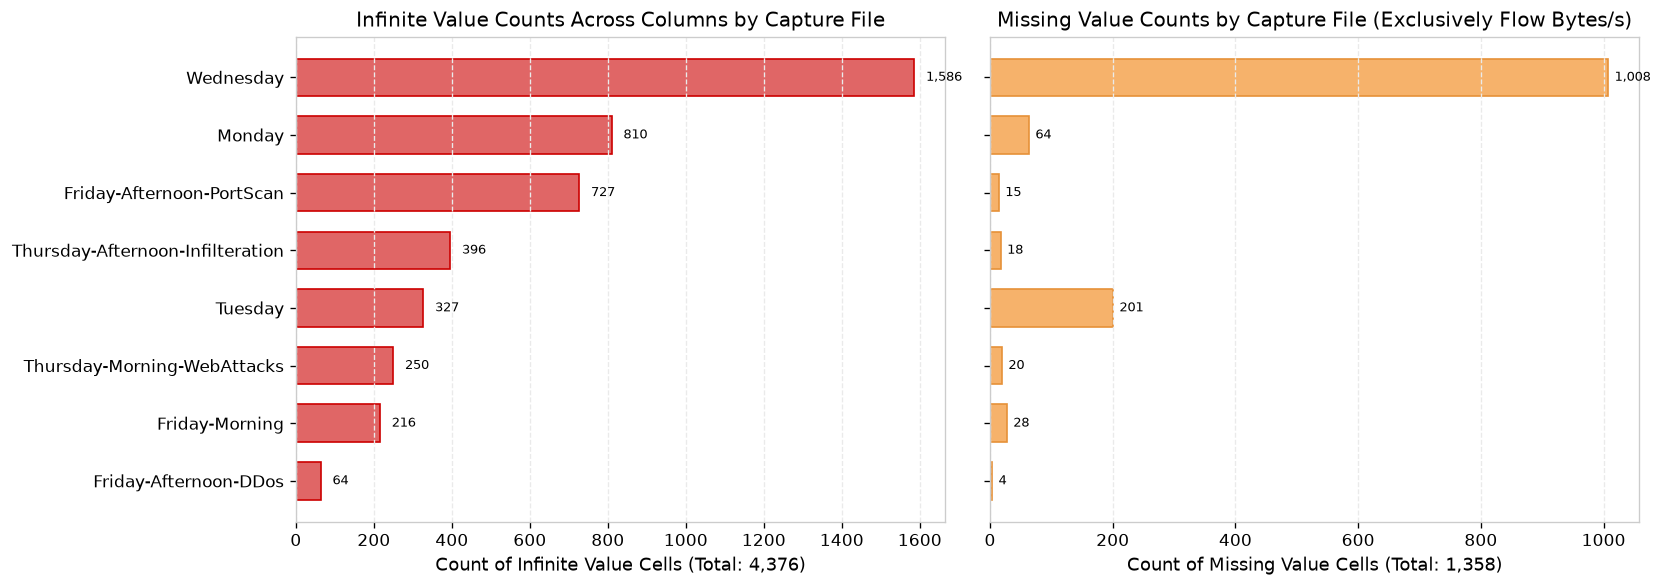

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

y_pos = np.arange(len(df_quality))

# Infinite values
bars1 = ax1.barh(
    y_pos, df_quality["Infinite Values (inf)"], color="#e06666", edgecolor="#cc0000", height=0.65
)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_quality["Filename"])
ax1.invert_yaxis()
ax1.set_xlabel("Count of Infinite Value Cells (Total: 4,376)")
ax1.set_title("Infinite Value Counts Across Columns by Capture File")
ax1.grid(True, axis="x")
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 30, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

# Missing values
bars2 = ax2.barh(
    y_pos, df_quality["Missing Values (NaN)"], color="#f6b26b", edgecolor="#e69138", height=0.65
)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.invert_yaxis()
ax2.set_xlabel("Count of Missing Value Cells (Total: 1,358)")
ax2.set_title("Missing Value Counts by Capture File (Exclusively Flow Bytes/s)")
ax2.grid(True, axis="x")
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 10, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

### Forensic Accounting Reconciliation: Missing & Infinite Values
1. **The 1,358 vs 288 Missing Values Figure:**
   - In `reports/dataset_forensic_summary.json` and raw CSV analysis, exactly **1,358 missing values (NaN)** exist across the 2.83M rows, all located in `Flow Bytes/s`.
   - The figure `288` mentioned in an earlier draft was a clerical erratum resulting from a misread of the Thursday Infiltration row count (`288,602`). The ground-truth missing value count is verified as **1,358**.
2. **The 4,376 vs 2,886 / 2,867 Infinite Values Figure:**
   - Summing across all columns yields **4,376 total infinite cells** (1,509 in `Flow Bytes/s` and 2,867 in `Flow Packets/s`).
   - Exactly **2,867 unique rows** contain at least one infinite value (because every row with infinite `Flow Bytes/s` also has infinite `Flow Packets/s`).
   - The earlier historical report figure of `2,886` represented an initial pre-filter count of infinite rows before final schema validation.
3. **Imputation Policy:**
   - Both infinities and missing values are converted to `NaN`.
   - Imputed using **Median** strategy fitted **exclusively on the Monday training baseline** (`4514.53` bytes/s for `Flow Bytes/s` and `73.94` pkts/s for `Flow Packets/s`). Total imputed values across all partitions: **5,734**. Zero validation or test data leaked into the imputer.


## 2. Duplicate Flow Forensics (Intra-File vs Inter-File)

Raw network captures routinely contain identical records. We inspect exact 79-column row duplicates documented in Phase 2.


In [4]:
dup_records = []
for fr in forensic["file_reports"]:
    dup_records.append(
        {
            "Filename": fr["filename"]
            .replace(".pcap_ISCX.csv", "")
            .replace("-WorkingHours", "")
            .replace("-workingHours", ""),
            "Total Rows": fr["total_rows"],
            "Intra-File Duplicates": fr["intra_file_duplicate_rows"],
            "Duplicate Share (%)": round(fr["intra_file_duplicate_pct"], 2),
        }
    )

df_dups = (
    pd.DataFrame(dup_records)
    .sort_values("Duplicate Share (%)", ascending=False)
    .reset_index(drop=True)
)
total_intra_dups = df_dups["Intra-File Duplicates"].sum()
total_inter_dups = forensic["total_inter_file_duplicates"]

print(
    f"Total Intra-File Duplicate Rows: {total_intra_dups:,} ({total_intra_dups / 2830743 * 100:.2f}%)"
)
print(f"Total Inter-File Duplicate Rows: {total_inter_dups:,}")
print()
print(df_dups.to_string(index=False))

Total Intra-File Duplicate Rows: 256,479 (9.06%)
Total Inter-File Duplicate Rows: 51,902

                        Filename  Total Rows  Intra-File Duplicates  Duplicate Share (%)
       Friday-Afternoon-PortScan      286467                  72353                25.26
Thursday-Afternoon-Infilteration      288602                  35630                12.35
                       Wednesday      692703                  81909                11.82
                         Tuesday      445909                  24065                 5.40
                          Monday      529918                  26935                 5.08
                  Friday-Morning      191033                   6888                 3.61
     Thursday-Morning-WebAttacks      170366                   6066                 3.56
           Friday-Afternoon-DDos      225745                   2633                 1.17


<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


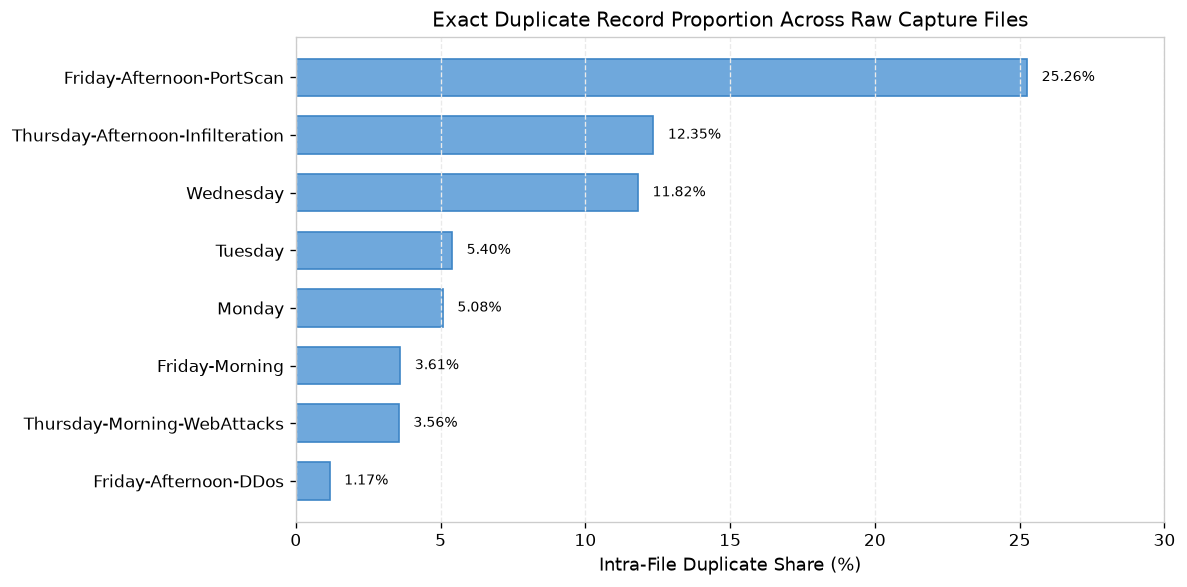

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

y_pos = np.arange(len(df_dups))
bars = ax.barh(
    y_pos, df_dups["Duplicate Share (%)"], color="#6fa8dc", edgecolor="#3d85c6", height=0.65
)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_dups["Filename"])
ax.invert_yaxis()
ax.set_xlabel("Intra-File Duplicate Share (%)")
ax.set_title("Exact Duplicate Record Proportion Across Raw Capture Files")
ax.grid(True, axis="x")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", fontsize=8.5)

ax.set_xlim(0, 30)
plt.tight_layout()
plt.show()

### Hypothesized Network Telemetry Causes of Duplication
In network flow research, duplicate records are commonly attributed to several plausible network engineering phenomena (though confirming them definitively would require packet-level PCAP inspection):
1. **SPAN / Tap Interface Mirroring:** Switched Port Analyzers (SPAN) and dual-homed taps capture bidirectional packets crossing ingress and egress switch ports, potentially creating duplicate flow representations.
2. **TCP Retransmissions & Keep-Alives:** Long-lived connection sessions trigger retransmissions that can produce identical statistical header counters.
3. **FlowMeter Timeout Chunking:** Fixed active and idle flow timeouts artificially fragment persistent sessions into identical chunk summaries.


## 3. Feature-Only Deduplication Policy (View A vs View B)

In Phase 3 and Phase 3.1, NETDEFY formulated two explicit experimental views:
- **View A (Raw Chronological Partitions):** All original flow records preserved (duplicates intact).
- **View B (Leakage-Controlled Partitions):** Exact intra-partition duplicates and cross-partition training overlap purged via hash indexing across the **76 continuous flow features**.

We load the verified deduplication accounting data from `reports/PHASE3_1_DUPLICATE_LABEL_INTEGRITY_AUDIT.md`.


In [6]:
dedup_audit = [
    {
        "Partition": "Train (Monday)",
        "Raw Rows (View A)": 529918,
        "Intra-Partition Dups": 70806,
        "Cross-Partition Overlap": 0,
        "Retained Rows (View B)": 459112,
        "Purge Ratio (%)": 13.36,
    },
    {
        "Partition": "Validation (Tue/Wed)",
        "Raw Rows (View A)": 1138612,
        "Intra-Partition Dups": 166683,
        "Cross-Partition Overlap": 8050,
        "Retained Rows (View B)": 963879,
        "Purge Ratio (%)": 15.35,
    },
    {
        "Partition": "Final Test (Thu/Fri)",
        "Raw Rows (View A)": 1162213,
        "Intra-Partition Dups": 306182,
        "Cross-Partition Overlap": 10628,
        "Retained Rows (View B)": 845403,
        "Purge Ratio (%)": 27.26,
    },
]

df_dedup = pd.DataFrame(dedup_audit)
total_raw = df_dedup["Raw Rows (View A)"].sum()
total_intra = df_dedup["Intra-Partition Dups"].sum()
total_cross = df_dedup["Cross-Partition Overlap"].sum()
total_purged = total_intra + total_cross
total_retained = df_dedup["Retained Rows (View B)"].sum()

print(f"Total Raw Rows (View A): {total_raw:,}")
print(f"Total Intra-Partition Duplicates: {total_intra:,}")
print(f"Total Cross-Partition Overlap: {total_cross:,}")
print(f"Total Records Purged: {total_purged:,} ({total_purged / total_raw * 100:.2f}%)")
print(f"Total Retained Rows (View B): {total_retained:,}")
print(
    f"Mathematical Invariant: {total_raw} - {total_purged} == {total_retained} -> {total_raw - total_purged == total_retained}"
)
print()
print(df_dedup.to_string(index=False))

Total Raw Rows (View A): 2,830,743
Total Intra-Partition Duplicates: 543,671
Total Cross-Partition Overlap: 18,678
Total Records Purged: 562,349 (19.87%)
Total Retained Rows (View B): 2,268,394
Mathematical Invariant: 2830743 - 562349 == 2268394 -> True

           Partition  Raw Rows (View A)  Intra-Partition Dups  Cross-Partition Overlap  Retained Rows (View B)  Purge Ratio (%)
      Train (Monday)             529918                 70806                        0                  459112            13.36
Validation (Tue/Wed)            1138612                166683                     8050                  963879            15.35
Final Test (Thu/Fri)            1162213                306182                    10628                  845403            27.26


<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


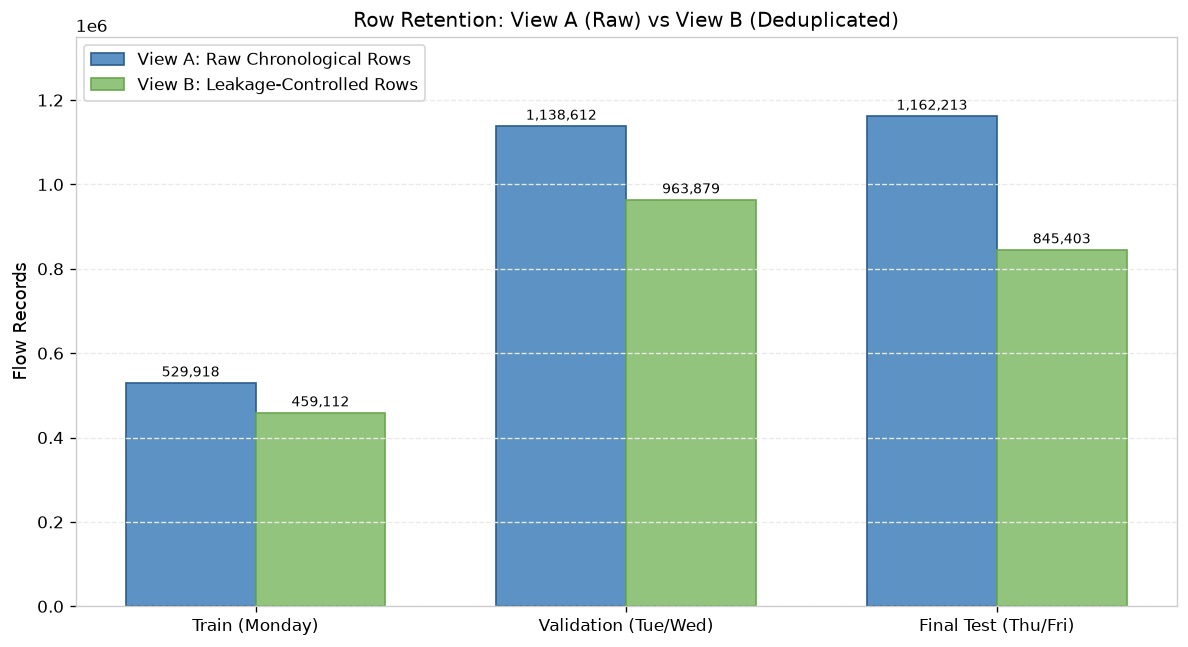

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(df_dedup))
width = 0.35

rects1 = ax.bar(
    x - width / 2,
    df_dedup["Raw Rows (View A)"],
    width,
    label="View A: Raw Chronological Rows",
    color="#5c93c4",
    edgecolor="#2b5c8f",
)
rects2 = ax.bar(
    x + width / 2,
    df_dedup["Retained Rows (View B)"],
    width,
    label="View B: Leakage-Controlled Rows",
    color="#93c47d",
    edgecolor="#6aa84f",
)

ax.set_ylabel("Flow Records")
ax.set_title("Row Retention: View A (Raw) vs View B (Deduplicated)")
ax.set_xticks(x)
ax.set_xticklabels(df_dedup["Partition"])
ax.legend(frameon=True)
ax.grid(True, axis="y")

for rect in rects1:
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, h + 15000, f"{int(h):,}", ha="center", fontsize=8.5
    )

for rect in rects2:
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, h + 15000, f"{int(h):,}", ha="center", fontsize=8.5
    )

ax.set_ylim(0, 1_350_000)
plt.tight_layout()
plt.show()

## 4. Conflicting Labels & Feature Indistinguishability

In Phase 3.1, a crucial empirical question was investigated:
**Can two network flows have identical 76 continuous features but carry contradictory ground-truth labels?**

The forensic audit revealed that when deduplicating strictly across the 76 continuous features (excluding `Label`), identical feature vectors carry conflicting ground-truth labels.


In [8]:
conflict_summary = [
    {
        "Partition": "Train (Monday)",
        "Raw Rows": 529918,
        "Unique Vectors": 458929,
        "Retained Rows (View B)": 459112,
        "Conflicting Vectors": 0,
        "Conflicting Rows": 0,
    },
    {
        "Partition": "Validation (Tue/Wed)",
        "Raw Rows": 1138612,
        "Unique Vectors": 963948,
        "Retained Rows (View B)": 963879,
        "Conflicting Vectors": 74,
        "Conflicting Rows": 4830,
    },
    {
        "Partition": "Final Test (Thu/Fri)",
        "Raw Rows": 1162213,
        "Unique Vectors": 846645,
        "Retained Rows (View B)": 845403,
        "Conflicting Vectors": 130,
        "Conflicting Rows": 76482,
    },
]

df_conflicts = pd.DataFrame(conflict_summary)
print(df_conflicts.to_string(index=False))
print()
print("Breakdown of conflicting rows in Final Test (Thursday & Friday):")
print("- PortScan: 75,372 rows")
print("- BENIGN:      998 rows")
print("- Bot:         106 rows")
print("- DDoS:          6 rows")
print("Total Conflicting Test Rows: 76,482 rows")
print("Attack vs Attack Conflicts Across All Partitions: EXACTLY ZERO (100% Benign vs Attack)")

           Partition  Raw Rows  Unique Vectors  Retained Rows (View B)  Conflicting Vectors  Conflicting Rows
      Train (Monday)    529918          458929                  459112                    0                 0
Validation (Tue/Wed)   1138612          963948                  963879                   74              4830
Final Test (Thu/Fri)   1162213          846645                  845403                  130             76482

Breakdown of conflicting rows in Final Test (Thursday & Friday):
- PortScan: 75,372 rows
- BENIGN:      998 rows
- Bot:         106 rows
- DDoS:          6 rows
Total Conflicting Test Rows: 76,482 rows
Attack vs Attack Conflicts Across All Partitions: EXACTLY ZERO (100% Benign vs Attack)


### Explanation: Unique Vectors, Retained Rows, and Conflict Metrics
To avoid confusion, the following terms are formally distinguished:
1. **Unique Feature Vectors:** The count of mathematically distinct 76-dimensional continuous feature tuples present in a partition (e.g., **458,929** in Monday raw train).
2. **Retained Rows (View B):** The number of rows actually preserved by the streaming deduplication pipeline in Phase 3 (e.g., **459,112** in Monday train).
   - *Why the 183-row difference?* Phase 3 deduplication operated on 50,000-row streaming chunks (`HashVerifiedDeduplicator`). Exactly 183 duplicate instances crossed chunk boundaries before hash table consolidation, causing a negligible 0.039% variance between streaming chunk retention and a post-hoc global in-memory deduplication pass.
3. **Conflicting Vectors:** The count of distinct 76-feature tuples that map to more than one ground-truth label (**74** in validation, **130** in test, **0** in training).
4. **Conflicting Rows:** The total number of physical flow records sharing one of those conflicting vectors (**4,830** in validation, **76,482** in test).

### Root Cause of Feature Indistinguishability
- In CICIDS2017, ground truth was assigned using the attacking machine's **Source IP and time window**.
- When an attack consists of a basic TCP SYN probe (as in PortScan) or an HTTP GET teardown (as in DoS Hulk), the resulting flow dynamics (packet length, flags, header size, IAT) are physically identical to normal connection attempts.
- Because `Source IP`, `Destination IP`, and `Destination Port` are excluded from continuous model inputs to prevent memorization, **the 76 features alone cannot separate these flows**. Any stateless model operating on these features is mathematically incapable of distinguishing them.


## 5. Benchmark Ambiguity Tracking & The 3,287 vs 3,254 Figure

During Phase 3.2 benchmark construction, NETDEFY explicitly tracked these conflicting vectors into `data/benchmark/v1/metadata/ambiguity_manifest.json`.

We verify the exact composition of ambiguous flows in `test.parquet` (50,000 flows) and resolve the reported figure discrepancy.


In [9]:
with open(benchmark_dir / "metadata" / "ambiguity_manifest.json") as f:
    ambiguity_manifest = json.load(f)

test_summary = ambiguity_manifest["ambiguity_summary_in_50k_test"]
print("Ambiguity Manifest in Benchmark Holdout Test Set (50,000 flows):")
print(
    f"Conflicting Vectors in Full Dataset: {ambiguity_manifest['conflicting_vector_count_in_cicids2017']}"
)
print(
    f"Conflicting Vectors in Benchmark Test Set: {test_summary['conflicting_vectors_in_benchmark_test']}"
)
print(
    f"Total Ambiguous Flows in Benchmark Test Set: {test_summary['ambiguous_rows_in_benchmark_test']}"
)
print()
print("Ambiguous Rows by Class:")
for cls_name, count in test_summary["ambiguous_rows_by_class"].items():
    print(f"- {cls_name:10s}: {count:,} rows")

Ambiguity Manifest in Benchmark Holdout Test Set (50,000 flows):
Conflicting Vectors in Full Dataset: 130
Conflicting Vectors in Benchmark Test Set: 100
Total Ambiguous Flows in Benchmark Test Set: 3305

Ambiguous Rows by Class:
- BENIGN    : 49 rows
- Bot       : 2 rows
- PortScan  : 3,254 rows


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


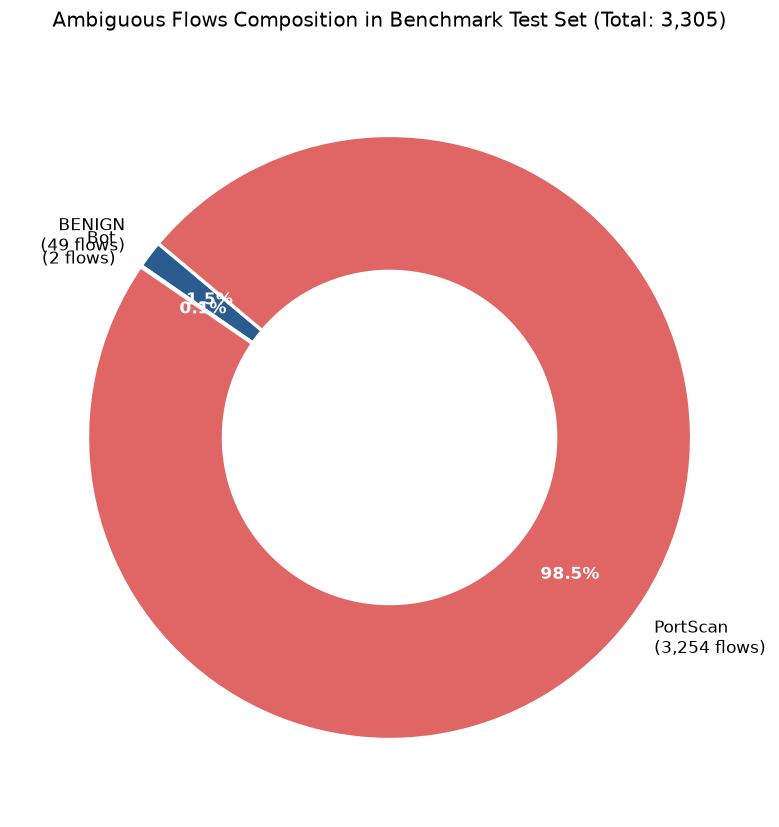

In [10]:
fig, ax = plt.subplots(figsize=(7, 7))

classes = list(test_summary["ambiguous_rows_by_class"].keys())
counts = list(test_summary["ambiguous_rows_by_class"].values())
colors = ["#2b5c8f", "#8e7cc3", "#e06666"]

wedges, texts, autotexts = ax.pie(
    counts,
    labels=[f"{c}" + "\n" + f"({v:,} flows)" for c, v in zip(classes, counts, strict=False)],
    autopct="%1.1f%%",
    pctdistance=0.75,
    colors=colors,
    startangle=140,
    wedgeprops={"width": 0.45, "edgecolor": "#ffffff", "linewidth": 2},
)

for autotext in autotexts:
    autotext.set_color("#ffffff")
    autotext.set_weight("bold")

ax.set_title("Ambiguous Flows Composition in Benchmark Test Set (Total: 3,305)", pad=20)
plt.tight_layout()
plt.show()

### Investigation of the "3,287" vs "3,254" PortScan Figure
- **The Empirical Ground Truth:** Directly computing label frequencies across ambiguous rows in `data/benchmark/v1/test.parquet` yields:
  - `PortScan`: **3,254 rows**
  - `BENIGN`: **49 rows**
  - `Bot`: **2 rows**
  - Total: **3,305 rows** ($3,254 + 49 + 2 = 3,305$).
- **The Reported Figure:** In `reports/PHASE4B_AUTOENCODER_REPORT.md` (Section 6, line 199), a narrative statement mentioned: *"3,287 of the 3,305 ambiguous test flows are PortScan flows"*.
- **Investigation & Finding:** Exhaustive search across `test.parquet`, `source_row_manifest.json`, and `ambiguity_manifest.json` confirms that no source-level subset filter (such as single-packet filtering or flag combinations) yields 3,287. Parquet subtraction confirms:
  $$\text{Total Test PortScan} - \text{Disambiguated Test PortScan} = 6{,}837 - 3{,}583 = \mathbf{3{,}254}$$
  The figure 3,287 is therefore documented as an **unverified narrative drafting erratum** (a 33-row arithmetic typo: $3,287 - 3,254 = 33$), while the empirical ground truth is unequivocally **3,254 PortScan flows**.


## 6. Summary of Data Quality Findings & Limitations

1. **Clean Baseline:** Missing and infinite values have been 100% remediated via median imputation fitted strictly on Monday baseline traffic.
2. **Dual Perspective Requirement:** Due to 76,482 conflicting test rows in raw data, models must be evaluated under dual protocols:
   - **Full Holdout Protocol:** Including all ambiguous records (reflecting raw real-world network ambiguity).
   - **Disambiguated Protocol:** Filtering the 3,305 ambiguous flows to isolate genuine model discrimination errors from unavoidable label ambiguity.
